In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi")
image = BioImage(data_path)
data = image.xarray_dask_data

In [ ]:
import napari
v = napari.Viewer()
v.add_image(image.data, channel_axis=1)

# 2. Drift correction

In [8]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

X DX 0.09922006548175864
X VX 0.09922006548175864
Y DY 0.09922006548175863
Y VY 0.09922006548175863


Text(0, 0.5, 'shift [um]')

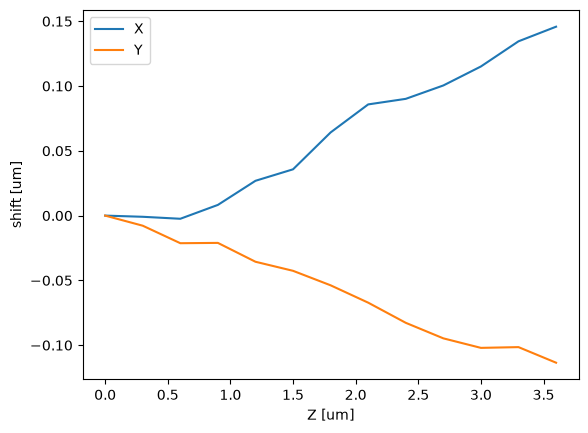

In [9]:
import matplotlib.pyplot as plt
shift.reset_index()["Z"]
plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X","Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

TypeError: string indices must be integers, not 'str'

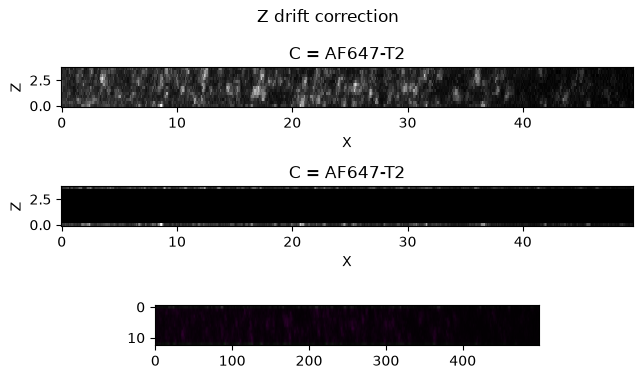

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
n = 500
a = data[0,1,:,:n,:n].max(axis=1)
b = stabilized[0,1,:,:n,:n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False,cmap='gray')
plt.subplot(312)
b.plot(add_colorbar=False,cmap='gray')
plt.subplot(313)
plt.imshow(np.stack([a,b,a],axis=2),aspect=4)
plt.suptitle('Z drift correction')
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 2. Spot detection

In [ ]:
# from spotiflow.model import Spotiflow
# import matplotlib.pyplot as plt
# import numpy as np

# model = Spotiflow.from_pretrained("general")
# tmp = stabilized.data[0,2,:,:500,:500]
# points, details = model.predict(tmp)

# plt.imshow(np.sqrt(tmp),cmap='gray')
# plt.plot(points[:,1],points[:,0],'.',ms=20,mfc="none")

In [ ]:
from prrt_clustering import detect_puncta,plot_data,plot_points
import matplotlib.pyplot as plt
import numpy as np

tmp = stabilized[0,:]#,:,300:700,900:1500]

points = detect_puncta(tmp, scale_um=1.0, specificity=3.)
fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=True,fig=fig)
plot_points(points, ms=10, split=True, axes=axes)


In [ ]:
points["intensity"].hist(bins=1000)

In [ ]:
spoints = points[points["intensity"]>10000]
fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=True,fig=fig)
plot_points(spoints, ms=20, split=True, axes=axes)
len(spoints),len(points)

In [ ]:
import napari
v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
print(o)
v.add_image(tmp,scale=vx,translate=o, channel_axis=0)
for n,pts in points.groupby("C"):
    v.add_points(pts[["Z","Y","X"]], size=0.5, name=n)

## 3. Clustering
Cluster points to identify potential synapses.

In [ ]:
from prrt_clustering import clean_points_nn_gmm, clean_points_nn_if, clean_points_besag_gmm

clean = clean_points_besag_gmm(points)
clean = clean[clean["noise"]==False]  # noqa: E712
fig = plt.figure(figsize=(20,20))
fig,axes = plot_data(tmp,split=False,fig=fig)
plot_points(points,ms=5,split=True,axes=axes)
plot_points(clean,ms=20,split=False,axes=axes)
# print(clean)


In [ ]:
from prrt_clustering import cluster
_,clusters = cluster(clean, 1, 7)
fig = plt.figure(figsize=(10,10))
fig,axes = plot_data(tmp, split=False,fig=fig)
plot_points(clusters,ms=10,axes=axes)